In [43]:
!pip3 install numpy matplotlib

In [44]:
# Linear Least Squares demo in 3D
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Generate synthetic linear data
np.random.seed(42)

# True model parameters (plane: z = a*x + b*y + c)
a, b, c = 2.0, -1.0, 5.0

# Generate random x, y values
N = 100
x = np.random.uniform(-5, 5, N)
y = np.random.uniform(-5, 5, N)

# Compute noiseless z values
z_true = a * x + b * y + c

In [45]:
# 2. Add Gaussian noise
noise = np.random.normal(0, 1.2, N)
z_noisy = z_true + noise

In [48]:
# 3. Fit with Linear Least Squares
# Design matrix [x, y, 1]
A = np.vstack([x, y, np.ones(N)]).T

# Solve the system Ax = b
# |x_0 y_0 1| |a|   |z_0|
# | .   .  .| |b| = | . |
# |x_n y_n 1| |c|   |z_n|
params, _, _, _ = np.linalg.lstsq(A.T @ A, A.T @ z_noisy)
a_hat, b_hat, c_hat = params

print("True parameters:   a=%.2f, b=%.2f, c=%.2f" % (a, b, c))
print("Estimated params:  a=%.2f, b=%.2f, c=%.2f" % (a_hat, b_hat, c_hat))

# Compute RMSE
z_pred = A @ params
rmse = np.sqrt(np.mean((z_noisy - z_pred)**2))
print("RMSE: %.3f" % rmse)


True parameters:   a=2.00, b=-1.00, c=5.00
Estimated params:  a=1.96, b=-0.91, c=5.12
RMSE: 1.167


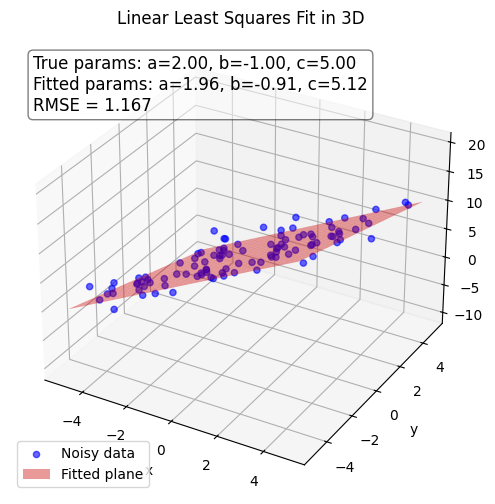

In [47]:
# 4. Plot results
fig = plt.figure(figsize=(12,6))
ax = fig.add_subplot(111, projection="3d")

# Scatter noisy data
ax.scatter(x, y, z_noisy, color="blue", alpha=0.6, label="Noisy data")

# Plot fitted plane
xx, yy = np.meshgrid(np.linspace(-5, 5, 20), np.linspace(-5, 5, 20))
zz = a_hat * xx + b_hat * yy + c_hat
ax.plot_surface(xx, yy, zz, alpha=0.4, color="red", label="Fitted plane")

# Annotate parameters and RMSE
textstr = '\n'.join((
    f"True params: a={a:.2f}, b={b:.2f}, c={c:.2f}",
    f"Fitted params: a={a_hat:.2f}, b={b_hat:.2f}, c={c_hat:.2f}",
    f"RMSE = {rmse:.3f}"
))
ax.text2D(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
          verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))


ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Linear Least Squares Fit in 3D")
plt.legend()
plt.show()